# Лабораторная работа №3

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-21 00:00:00,77.606167
1,2026-11-21 01:00:00,77.809007
2,2026-11-21 02:00:00,66.221119
3,2026-11-21 03:00:00,76.602630
4,2026-11-21 04:00:00,44.947280


### Необходимые преобразования

In [3]:
def adjust_df(df_orig):
    # Сортировка и проверка дубликатов
    df = df_orig.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")

    # Установка временного индекса и проверка частоты
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)
    df.index.name = "timestamp"

    return df

In [4]:
df = adjust_df(df)
df.head()

,value
timestamp,
2026-11-21 00:00:00,77.606167
2026-11-21 01:00:00,77.809007
2026-11-21 02:00:00,66.221119
2026-11-21 03:00:00,76.602630
2026-11-21 04:00:00,44.947280


### График ряда

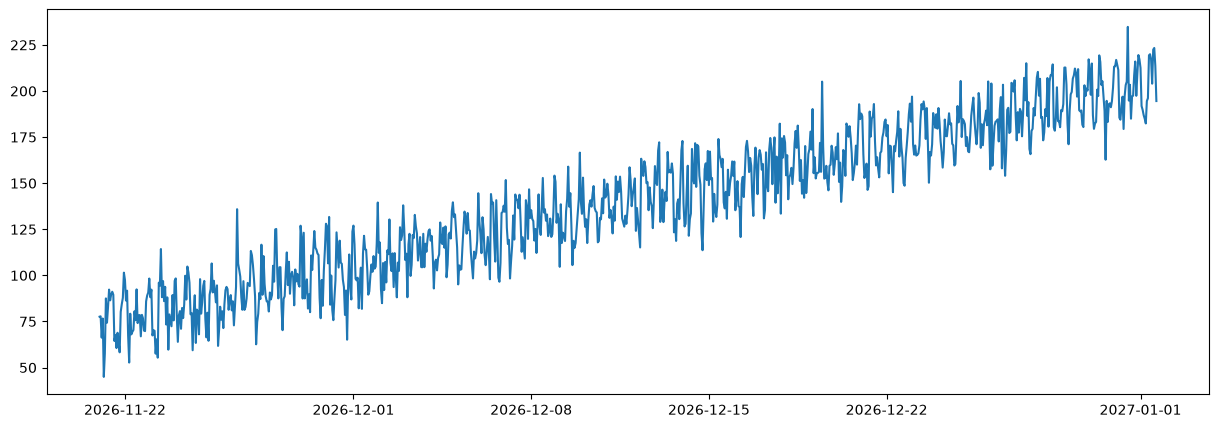

In [5]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["value"], label="y")
plt.show()

### Автокоррелирующая функция

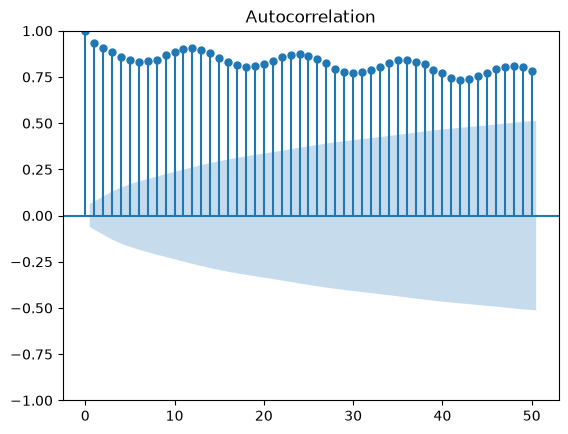

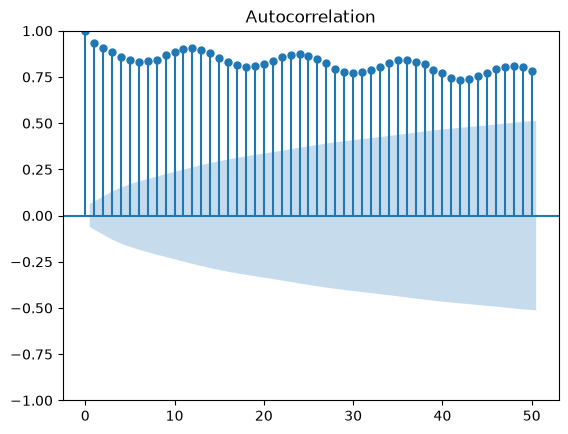

In [14]:
plot_acf(df, lags=50)

Наблюдается медленное затухание - ряд **нестационарен**